In [1]:
# import libraries
import pandas as pd 
import numpy as np 
from sklearn.model_selection import train_test_split
import category_encoders as ce 
from sklearn import metrics
import matplotlib.pyplot as plt 
import seaborn as sns 
import time
import warnings
from sklearn import tree
from sklearn import ensemble 
import hyperopt
from hyperopt import hp, tpe, fmin, Trials
from sklearn import preprocessing
from sklearn import model_selection
from sklearn.ensemble import AdaBoostClassifier

In [2]:
# load data
train_data = pd.read_csv('data/train.csv')
test_data = pd.read_csv('data/test.csv')
id = test_data['PassengerId']

In [3]:
# feature engineering
def extract_title(name):
    return name.split(',')[1].split('.')[0].strip()

for df in [train_data, test_data]:
    df['Title'] = df['Name'].apply(extract_title)
    rare_titles = ['Lady','Countess','Capt','Col','Don','Dr','Major','Rev','Sir','Jonkheer','Dona']
    df['Title'] = df['Title'].replace(rare_titles, 'Rare')
    df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
    df['IsAlone'] = (df['FamilySize']==1).astype(int)
    df['HasCabin'] = (~df['Cabin'].isnull()).astype(int)
    df['Deck'] = df['Cabin'].fillna('U').astype(str).str[0]
    df['FarePerPerson'] = df['Fare'] / df['FamilySize']

age_medians = train_data.groupby('Title')['Age'].median()
train_data['Age'] = train_data.apply(lambda r: age_medians[r['Title']] if pd.isna(r['Age']) else r['Age'], axis=1)
test_data['Age'] = test_data.apply(lambda r: age_medians.get(r['Title'], test_data['Age'].median()) if pd.isna(r['Age']) else r['Age'], axis=1)


In [4]:
# detect and handle outliers
def outliers_iqr(data, feature):
    x = train_data[feature]
    quantile_1, quantile_3 = x.quantile(0.25), x.quantile(0.75)
    iqr = quantile_3 - quantile_1
    lower_bound = quantile_1 - (iqr * 1.5)
    upper_bound = quantile_3 + (iqr * 1.5)
    outliers = data[(x<lower_bound) | (x>upper_bound)]
    clean = data[(x>lower_bound) & (x<upper_bound)]
    return outliers

outliers_train = outliers_iqr(train_data, 'Parch') 
outliers_test = outliers_iqr(test_data, 'Parch')
mask_parch_train = outliers_train[outliers_train['Parch']>3]
mask_parch_test = outliers_test[outliers_test['Parch']>2]

/var/folders/hn/rkx7w4655nl9_69nk9yhtb780000gn/T/ipykernel_14763/3336281217.py:8: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  outliers = data[(x<lower_bound) | (x>upper_bound)]
/var/folders/hn/rkx7w4655nl9_69nk9yhtb780000gn/T/ipykernel_14763/3336281217.py:9: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  clean = data[(x>lower_bound) & (x<upper_bound)]


In [5]:
# detect and handle missing values
train_data = train_data.drop(['Cabin', 'PassengerId', 'Name', 'Ticket'], axis=1)
train_data['Age'] = train_data['Age'].fillna(float(24))
train_data = train_data.drop(mask_parch_train.index, axis=0)
train_data = train_data.dropna()

# the ticket number is dropped: binary-encoding hundreds of unique ticket strings only adds noise
test_data = test_data.drop(['Cabin', 'PassengerId', 'Name', 'Ticket'], axis=1)
test_data['Age'] = test_data['Age'].fillna(float(24))
test_data['Fare'] = test_data['Fare'].fillna(train_data['Fare'].median())

In [6]:
# encode categorical features
# the encoder is fitted on the training set only and then applied to both sets,
# so every column means the same category in train and test
cat_cols = ['Sex', 'Embarked', 'Title', 'Deck']
encoder_onehot = ce.OneHotEncoder(cols=cat_cols, use_cat_names=True, handle_unknown='value')
encoder_onehot.fit(train_data[cat_cols])

train_data = pd.concat([train_data.drop(cat_cols, axis=1), encoder_onehot.transform(train_data[cat_cols])], axis=1)
test_data = pd.concat([test_data.drop(cat_cols, axis=1), encoder_onehot.transform(test_data[cat_cols])], axis=1)

print(train_data.shape, test_data.shape)

(879, 33) (418, 32)


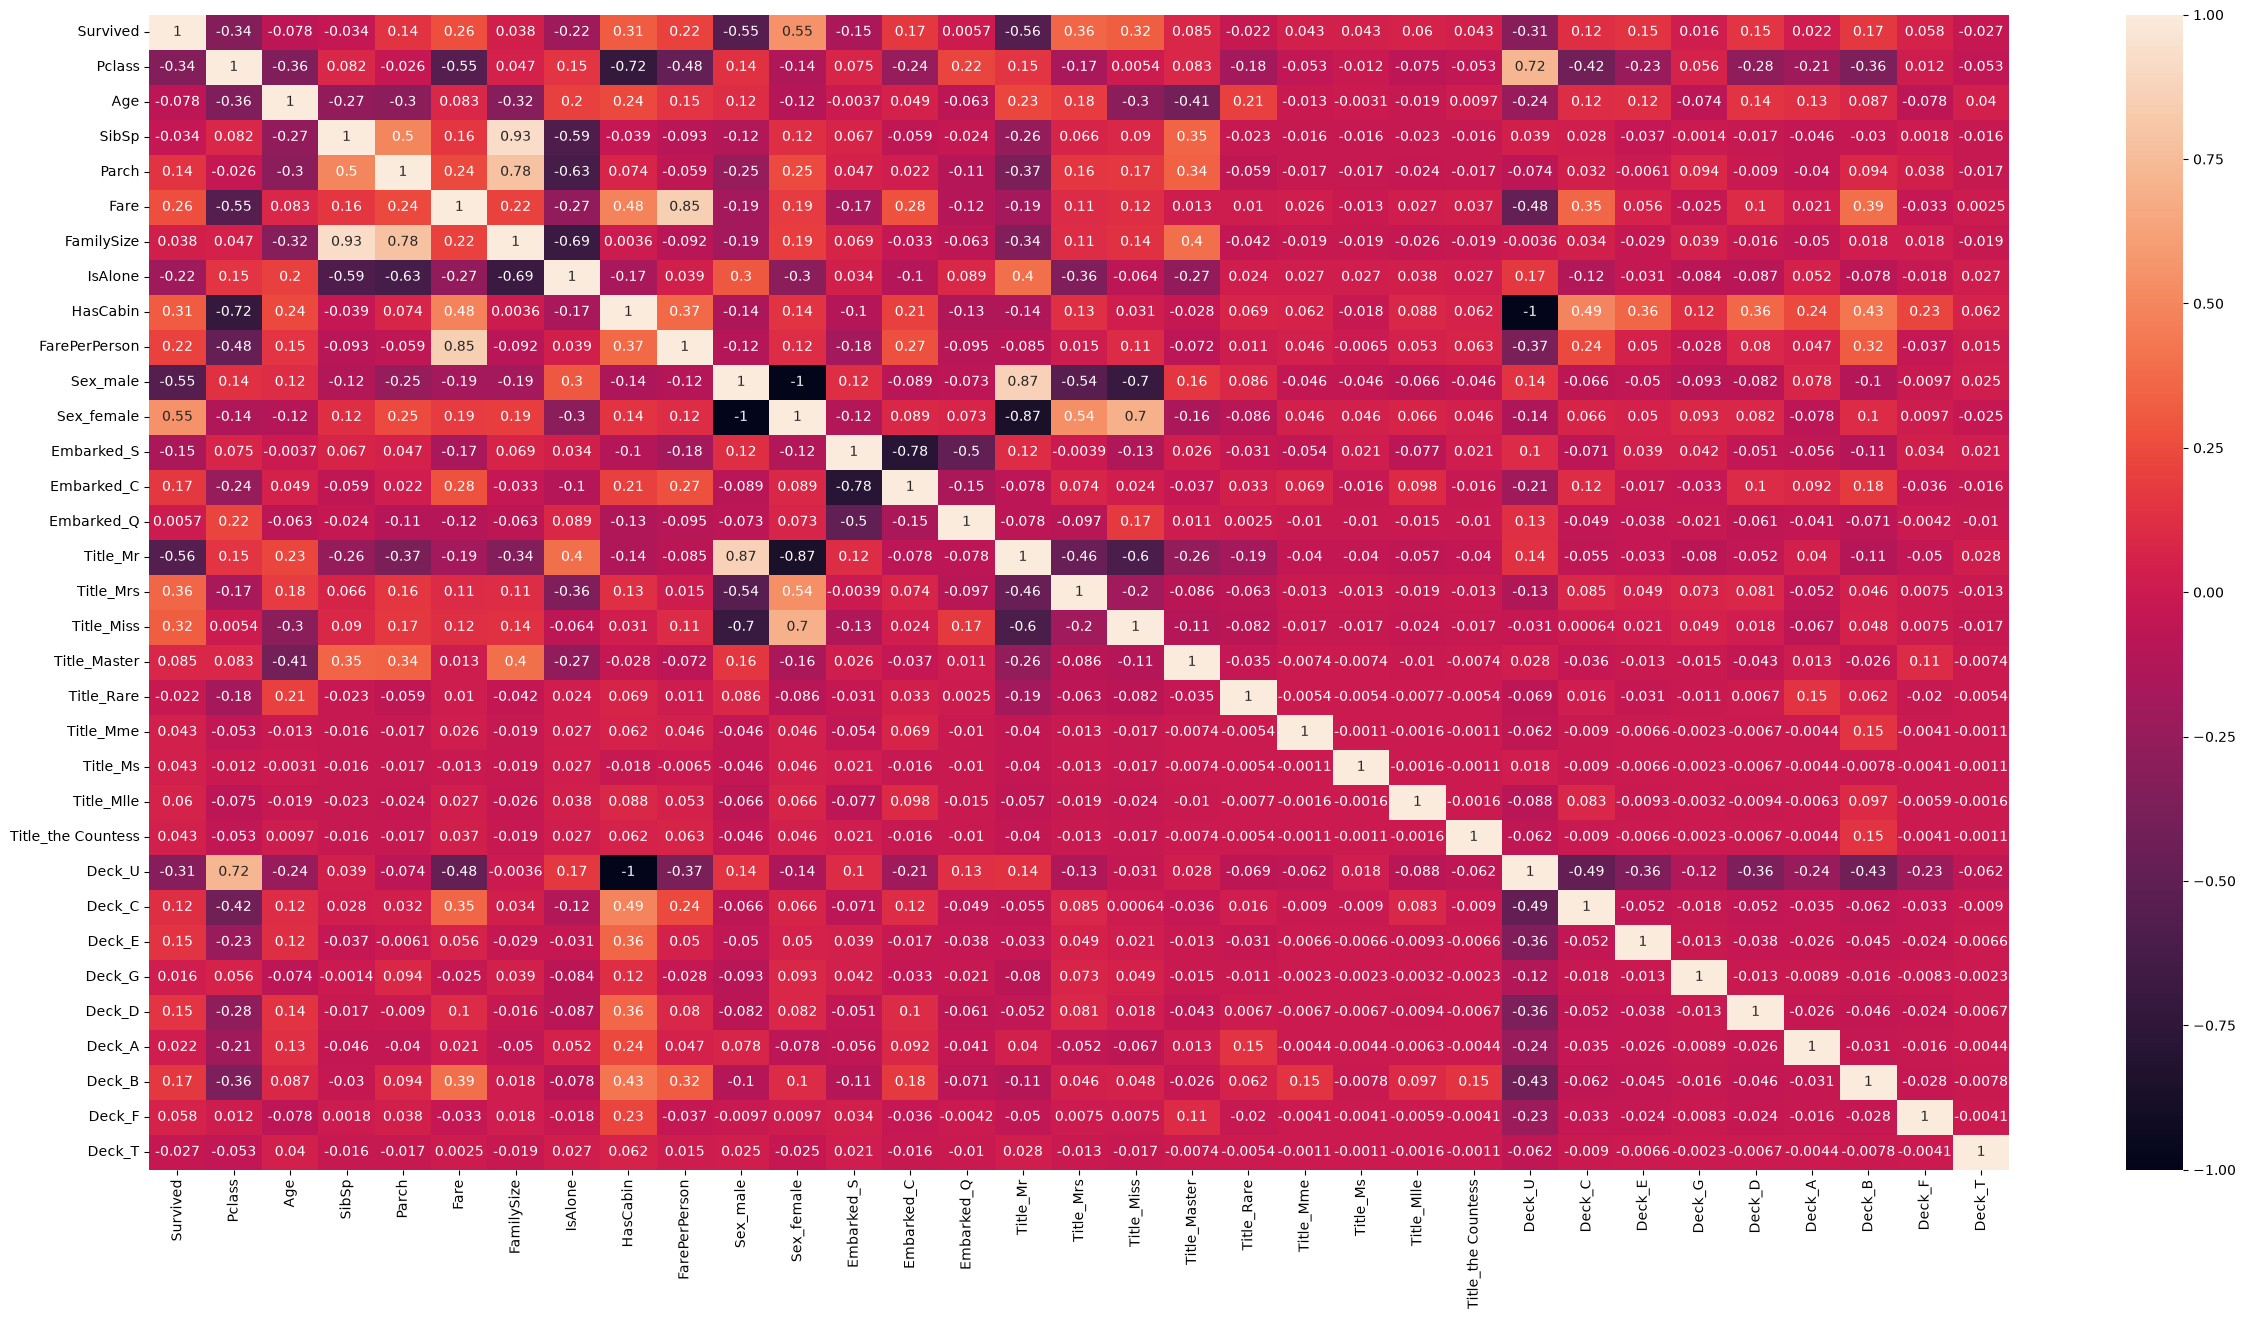

In [7]:
# examine correlation matrix
corr_matrix = train_data.corr()
fig, ax = plt.subplots(figsize=(30, 15))
sns.heatmap(train_data.corr(), annot=True, ax=ax)
plt.show()

In [8]:
# split data into training and test sets
X = train_data.drop('Survived', axis=1)
y = train_data['Survived']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [9]:
# perform hyperparameter tuning
# each set of parameters is scored by 5-fold cross-validation on the training split,
# not on the data the tree was fitted on, otherwise the deepest tree always wins
warnings.filterwarnings('ignore')

space = {'max_depth': hp.quniform('max_depth', 1, 7, 1),
         'min_samples_leaf': hp.quniform('min_samples_leaf', 1, 100, 1),
         'criterion': hp.choice('criterion', ['entropy', 'gini']),
         'class_weight': hp.choice('class_weight', ['balanced', None])}

random_state = 42
skf = model_selection.StratifiedKFold(n_splits=5, shuffle=True, random_state=random_state)

def to_tree_params(params):
    return {'max_depth': int(params['max_depth']),
            'min_samples_leaf': int(params['min_samples_leaf']),
            'criterion': params['criterion'],
            'class_weight': params['class_weight']}

def hyperopt_tree(params):
    model = tree.DecisionTreeClassifier(**to_tree_params(params), random_state=random_state)
    score = model_selection.cross_val_score(model, X_train, y_train, cv=skf, scoring='accuracy').mean()
    return -score

trials = Trials()

best = fmin(hyperopt_tree,
            max_evals=100,
            trials=trials,
            space=space,
            algo=tpe.suggest,
            rstate=np.random.default_rng(random_state))

best_params = to_tree_params(hyperopt.space_eval(space, best))
print(best_params)
print(f"best CV accuracy during tuning: {-min(trials.losses()):.3f}")

  0%|          | 0/100 [00:00<?, ?trial/s, best loss=?]

 14%|█▍        | 14/100 [00:00<00:00, 137.05trial/s, best loss: -0.8477608915906789]

 28%|██▊       | 28/100 [00:00<00:00, 134.95trial/s, best loss: -0.8477608915906789]

 42%|████▏     | 42/100 [00:00<00:00, 130.31trial/s, best loss: -0.8477608915906789]

 56%|█████▌    | 56/100 [00:00<00:00, 126.03trial/s, best loss: -0.8477608915906789]

 69%|██████▉   | 69/100 [00:00<00:00, 122.49trial/s, best loss: -0.8477608915906789]

 82%|████████▏ | 82/100 [00:00<00:00, 119.79trial/s, best loss: -0.8477608915906789]

 94%|█████████▍| 94/100 [00:00<00:00, 117.22trial/s, best loss: -0.8477608915906789]

100%|██████████| 100/100 [00:00<00:00, 121.43trial/s, best loss: -0.8477608915906789]


{'max_depth': 6, 'min_samples_leaf': 7, 'criterion': 'entropy', 'class_weight': None}
best CV accuracy during tuning: 0.848


In [10]:
# train decision tree model with the tuned parameters and evaluate it on the hold-out split
tree_model = tree.DecisionTreeClassifier(**best_params, random_state=42)

tree_model.fit(X_train, y_train)

y_train_predict = tree_model.predict(X_train)
y_test_predict = tree_model.predict(X_test)
print(f"train accuracy: {metrics.accuracy_score(y_train, y_train_predict):.3f}")
print(f"hold-out accuracy: {metrics.accuracy_score(y_test, y_test_predict):.3f}")

train accuracy: 0.861
hold-out accuracy: 0.767


In [11]:
# validate model performance with 10-fold stratified cross-validation on all labelled data
kf = model_selection.StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
cv_metrics = model_selection.cross_validate(
    estimator=tree_model,
    X=X,
    y=y,
    cv=kf,
    scoring='accuracy',
    return_train_score=True
)

print(f"CV accuracy: {cv_metrics['test_score'].mean():.3f} ± {cv_metrics['test_score'].std():.3f}")
print(f"train accuracy: {cv_metrics['train_score'].mean():.3f}")

CV accuracy: 0.809 ± 0.041
train accuracy: 0.866


In [12]:
# generate final predictions
tree_model.fit(X, y)
result_predict = tree_model.predict(test_data[X.columns])

In [13]:
# save results to CSV
result = pd.DataFrame({'PassengerId': id, 'Survived': result_predict})
result.to_csv('submission.csv', index=False)